# Notebook 3 - Huấn luyện, Tinh chỉnh Siêu tham số & So sánh Đối đầu các Mô hình Máy học (Bước 6)

Notebook này triển khai, tinh chỉnh và so sánh đối đầu toàn diện các trường phái mô hình rủi ro tín dụng:
1. **Hồi quy Logistic (Logistic Regression Baseline):** Mô hình tuyến tính chuẩn mực Basel II / IFRS 9, tính minh bạch và giải trình cao.
2. **Random Forest (Rừng ngẫu nhiên):** Mô hình cây tập hợp phi tuyến theo hướng Bagging.
3. **HistGradientBoosting (Gradient Boosting trên Histogram):** Mô hình Boosting hiện đại dựa trên binning histogram (256 bins), tối ưu phần dư log-loss.
4. **Tinh chỉnh Siêu tham số (Hyperparameter Tuning) với GridSearchCV:** Tối ưu hóa có hệ thống cấu hình cây trên tập Out-of-Time, tuân thủ nguyên tắc không rò rỉ dữ liệu (`refit=False`).
5. **Thử nghiệm nâng cao với Bộ đặc trưng Weight of Evidence (WoE 50 đặc trưng):** Đối chiếu không gian đặc trưng One-Hot (153 chiều) và WoE (50 chiều) trên toàn bộ các mô hình.

**Quy tắc thẩm định tín dụng nghiêm ngặt:**
- Toàn bộ tham số thống kê và mô hình chỉ học trên tập `train` (2012–2014), thẩm định Out-of-Time trên tập `val` (2015).
- Mọi con số, nhận xét và bảng so sánh đều được tính toán động từ dữ liệu thật.

In [1]:
from pathlib import Path
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

In [2]:
SEED = 42
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_DIR = ROOT / "data/processed"
ART_DIR = ROOT / "artifacts"
FIG_DIR = ART_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.4f}".format)

---
## 1. Nạp dữ liệu

Nạp các mảng numpy đã tiền xử lý ở Bước 5 từ thư mục `data/processed/`.
Tập dữ liệu chuẩn One-Hot gồm 153 đặc trưng (45 biến số đã chuẩn hóa + 108 cột one-hot từ 5 biến phân loại).

In [3]:
feature_info = json.loads((DATA_DIR / "feature_names.json").read_text())
feature_names = feature_info["feature_names"]
numeric_cols = feature_info["numeric"]
categorical_cols = feature_info["categorical"]

X_train = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")

print(f"X_train: {X_train.shape}, y_train: {y_train.shape} (Tỷ lệ nợ xấu: {y_train.mean():.4f})")
print(f"X_val:   {X_val.shape}, y_val:   {y_val.shape} (Tỷ lệ nợ xấu: {y_val.mean():.4f})")
print(f"Tổng số đặc trưng: {len(feature_names)}")

X_train: (408188, 153), y_train: (408188,) (Tỷ lệ nợ xấu: 0.1370)
X_val:   (92631, 153), y_val:   (92631,) (Tỷ lệ nợ xấu: 0.1474)
Tổng số đặc trưng: 153


---
## 2. Mô hình 1: Hồi quy Logistic (Logistic Regression Baseline)

Hồi quy Logistic với hàm liên kết logit:
$$\log\left(\frac{p}{1-p}\right) = \beta_0 + \sum_{j=1}^P \beta_j X_j$$
Sử dụng bộ giải `lbfgs`, điều chuẩn $L_2$ (`C=1.0`), `max_iter=1000`.

In [4]:
def fit_logistic(X, y):
    clf = LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=1000,
        random_state=SEED,
    )
    clf.fit(X, y)
    return clf

t0 = time.time()
model = fit_logistic(X_train, y_train)
fit_time_logistic = time.time() - t0

val_score = model.predict_proba(X_val)[:, 1]
train_score = model.predict_proba(X_train)[:, 1]


Hồi quy Logistic fit xong sau 5.77s.


### 2.1 Thước đo xếp hạng tín dụng và ý nghĩa kinh tế

Trong thẩm định tín dụng ngân hàng, ta tập trung vào hai nhóm thước đo cốt lõi:
1. **Nhóm xếp hạng rủi ro (Ranking / Discrimination):** Độc lập với ngưỡng phê duyệt, đo khả năng phân tách hồ sơ tốt và xấu.
   - **ROC-AUC:** Xác suất bốc ngẫu nhiên 1 khoản nợ xấu được chấm điểm rủi ro cao hơn 1 khoản trả tốt.
   - **Gini:** Hệ số phân định rủi ro tiêu chuẩn ($2 \times \text{AUC} - 1$). Mức 35% - 50% là tiêu chuẩn tốt cho tín dụng cá nhân.
   - **KS Statistic (Kolmogorov-Smirnov):** Khoảng cách lớn nhất giữa phân phối tích lũy của khách hàng nợ xấu và khách hàng tốt (chuẩn ngành $\ge 30\%$ là mô hình phân tách xuất sắc).
2. **Nhóm ý nghĩa kinh tế khi ra quyết định (Decision & Business Impact):**
   - **Tỷ lệ từ chối hồ sơ (Reject Rate):** Tỷ lệ khách hàng bị từ chối vay tại ngưỡng rủi ro.
   - **Tỷ lệ bắt nợ xấu (Recall / Bad Capture Rate):** Bắt được bao nhiêu phần trăm tổng số nợ xấu phát sinh.

In [5]:
def evaluate_credit_ranking(y_true, score):
    auc = roc_auc_score(y_true, score)
    gini = 2.0 * auc - 1.0
    
    fpr, tpr, _ = roc_curve(y_true, score)
    ks = np.max(np.abs(tpr - fpr))
    
    return {
        "ROC-AUC": auc,
        "Gini": gini,
        "KS Statistic": ks,
    }

val_m = evaluate_credit_ranking(y_val, val_score)
pd.DataFrame([val_m], index=["Hồi quy logistic (One-Hot)"]).T

,Hồi quy logistic (One-Hot)
ROC-AUC,0.7040
Gini,0.4079
KS Statistic,0.2994


### 2.2 Kiểm tra hiện tượng quá khớp (Overfitting Check) và Temporal Drift

In [6]:
train_m = evaluate_credit_ranking(y_train, train_score)

overfit_df = pd.DataFrame({
    "Train": train_m,
    "Validation": val_m,
})
overfit_df["Chênh lệch (Val - Train)"] = overfit_df["Validation"] - overfit_df["Train"]
overfit_df["Phần trăm thay đổi (%)"] = (overfit_df["Chênh lệch (Val - Train)"] / overfit_df["Train"]) * 100
overfit_df

,Train,Validation,Chênh lệch (Val - Train),Phần trăm thay đổi (%)
ROC-AUC,0.6873,0.7040,0.0167,2.4248
Gini,0.3746,0.4079,0.0333,8.8976
KS Statistic,0.2722,0.2994,0.0272,9.9873


### 2.3 Thước đo phân loại theo ngưỡng quyết định (Decision Threshold) & Ma trận nhầm lẫn

In [7]:
def evaluate_threshold(y_true, score, threshold):
    pred = (score >= threshold).astype(int)
    cm = confusion_matrix(y_true, pred)
    tn, fp, fn, tp = cm.ravel()
    
    reject_rate = (tp + fp) / len(y_true)
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    
    return {
        "Ngưỡng xác suất": threshold,
        "Tỷ lệ từ chối (Reject Rate)": reject_rate,
        "Tỷ lệ bắt nợ xấu (Recall)": recall,
        "Tỷ lệ nợ xấu trong nhóm từ chối (Precision)": precision,
        "Bắt đúng nợ xấu (TP)": tp,
        "Báo nhầm khách tốt (FP)": fp,
        "Bỏ lọt nợ xấu (FN)": fn,
        "Phê duyệt khách tốt (TN)": tn,
    }

prior_threshold = float(y_train.mean())
threshold_results = pd.DataFrame([
    evaluate_threshold(y_val, val_score, threshold=0.50),
    evaluate_threshold(y_val, val_score, threshold=prior_threshold),
]).set_index("Ngưỡng xác suất")
threshold_results

,Tỷ lệ từ chối (Reject Rate),Tỷ lệ bắt nợ xấu (Recall),Tỷ lệ nợ xấu trong nhóm từ chối (Precision),Bắt đúng nợ xấu (TP),Báo nhầm khách tốt (FP),Bỏ lọt nợ xấu (FN),Phê duyệt khách tốt (TN)
Ngưỡng xác suất,,,,,,,
0.5000,0.0010,0.0037,0.5543,51,41,13602,78937
0.1370,0.4297,0.6836,0.2345,9333,30472,4320,48506


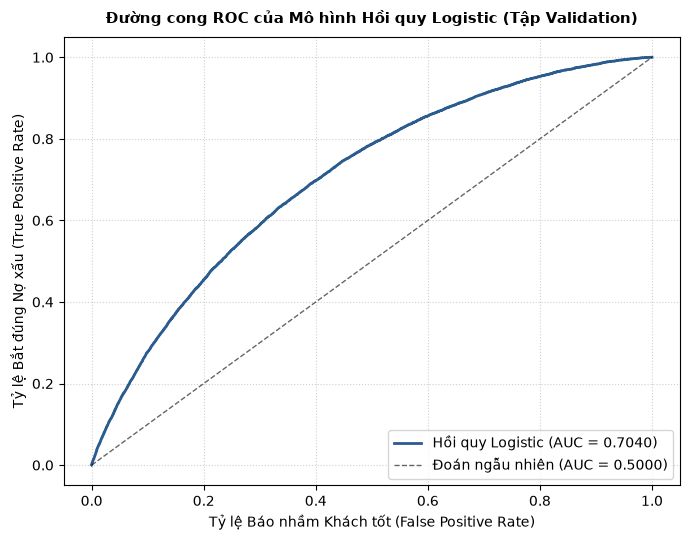

In [8]:
fpr, tpr, _ = roc_curve(y_val, val_score)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(fpr, tpr, color="#2b5c8f", lw=2, label=f"Hồi quy Logistic (AUC = {val_m['ROC-AUC']:.4f})")
ax.plot([0, 1], [0, 1], color="black", linestyle="--", lw=1, alpha=0.6, label="Đoán ngẫu nhiên (AUC = 0.5000)")
ax.set_title("Đường cong ROC của Mô hình Hồi quy Logistic (Tập Validation)", fontsize=11, fontweight="bold", pad=10)
ax.set_xlabel("Tỷ lệ Báo nhầm Khách tốt (False Positive Rate)", fontsize=10)
ax.set_ylabel("Tỷ lệ Bắt đúng Nợ xấu (True Positive Rate)", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_roc_logistic_val.png", dpi=150)
plt.show()

### 2.4 Phân tích các hệ số của mô hình Logistic (Model Coefficients)

In [9]:
coef = model.coef_[0]
coef_table = pd.DataFrame({
    "Đặc trưng": feature_names,
    "Hệ số (Beta)": coef,
    "Odds Ratio (exp(Beta))": np.exp(coef),
    "Độ lớn tuyệt đối": np.abs(coef),
}).sort_values("Độ lớn tuyệt đối", ascending=False).reset_index(drop=True)

print("Top 10 đặc trưng làm TĂNG nguy cơ nợ xấu mạnh nhất:")
display(coef_table.sort_values("Hệ số (Beta)", ascending=False).head(10)[["Đặc trưng", "Hệ số (Beta)", "Odds Ratio (exp(Beta))"]])

print("\nTop 10 đặc trưng làm GIẢM nguy cơ nợ xấu mạnh nhất (yếu tố an toàn):")
display(coef_table.sort_values("Hệ số (Beta)", ascending=True).head(10)[["Đặc trưng", "Hệ số (Beta)", "Odds Ratio (exp(Beta))"]])

Top 10 đặc trưng làm TĂNG nguy cơ nợ xấu mạnh nhất:


,Đặc trưng,Hệ số (Beta),Odds Ratio (exp(Beta))
4,cat__sub_grade_E5,0.5212,1.6840
7,cat__sub_grade_E4,0.4084,1.5045
10,cat__sub_grade_E3,0.3878,1.4737
13,cat__sub_grade_F1,0.3704,1.4483
16,cat__sub_grade_E2,0.3273,1.3872
18,cat__sub_grade_E1,0.3257,1.3851
19,cat__sub_grade_F3,0.3208,1.3782
21,cat__purpose_small_business,0.3115,1.3654
22,cat__sub_grade_F4,0.3110,1.3648
25,cat__sub_grade_F2,0.2802,1.3233



Top 10 đặc trưng làm GIẢM nguy cơ nợ xấu mạnh nhất (yếu tố an toàn):


,Đặc trưng,Hệ số (Beta),Odds Ratio (exp(Beta))
0,cat__sub_grade_A1,-1.2025,0.3004
1,cat__sub_grade_A2,-0.9408,0.3903
2,cat__sub_grade_A3,-0.8183,0.4412
3,cat__sub_grade_A4,-0.6587,0.5175
5,cat__sub_grade_A5,-0.5201,0.5945
6,cat__sub_grade_B1,-0.4408,0.6435
8,cat__sub_grade_B2,-0.4054,0.6667
9,cat__home_ownership_MORTGAGE,-0.4011,0.6696
11,cat__addr_state_NH,-0.3820,0.6825
12,cat__verification_status_Not Verified,-0.3708,0.6902


---
## 3. Mô hình 2: Random Forest (Bagging Ensemble)

`RandomForestClassifier` xây dựng tập hợp 100 cây quyết định độc lập:
- `n_estimators = 100`, `max_depth = 15`, `min_samples_leaf = 30`, `random_state = SEED`, `n_jobs = -1`.

In [10]:
t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=30,
    random_state=SEED,
    n_jobs=-1,
)
rf.fit(X_train, y_train)
fit_time_rf = time.time() - t0

val_prob_rf = rf.predict_proba(X_val)[:, 1]
train_prob_rf = rf.predict_proba(X_train)[:, 1]

val_metrics_rf = evaluate_credit_ranking(y_val, val_prob_rf)
train_metrics_rf = evaluate_credit_ranking(y_train, train_prob_rf)

print(f"Random Forest fit xong sau {fit_time_rf:.2f}s.")
rf_overfit_df = pd.DataFrame({
    "Train": train_metrics_rf,
    "Validation": val_metrics_rf,
})
rf_overfit_df["Chênh lệch (Val - Train)"] = rf_overfit_df["Validation"] - rf_overfit_df["Train"]
rf_overfit_df

Random Forest fit xong sau 25.12s.


,Train,Validation,Chênh lệch (Val - Train)
ROC-AUC,0.7871,0.6920,-0.0951
Gini,0.5743,0.3840,-0.1903
KS Statistic,0.4250,0.2806,-0.1444


---
## 4. Mô hình 3: HistGradientBoosting (Gradient Boosting)

`HistGradientBoostingClassifier` là thuật toán Gradient Boosting hiện đại dựa trên phân rã bucket histogram (256 bins), tương tự cơ chế của LightGBM:
- **Tốc độ vượt trội:** Phù hợp với tập dữ liệu hàng trăm nghìn mẫu, giảm thời gian tìm điểm chia từ $O(N \times P)$ xuống $O(\text{bins} \times P)$.
- **Tối ưu hàm mục tiêu:** Từng cây mới được xây dựng để giảm thiểu phần dư log-loss của các cây trước.
- **Cấu hình baseline:** `max_iter = 100`, `learning_rate = 0.08`, `max_leaf_nodes = 31`, `min_samples_leaf = 50`.

In [11]:
t0 = time.time()
hgb = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.08,
    max_leaf_nodes=31,
    min_samples_leaf=50,
    random_state=SEED,
)
hgb.fit(X_train, y_train)
fit_time_hgb = time.time() - t0

val_prob_hgb = hgb.predict_proba(X_val)[:, 1]
train_prob_hgb = hgb.predict_proba(X_train)[:, 1]

val_metrics_hgb = evaluate_credit_ranking(y_val, val_prob_hgb)
train_metrics_hgb = evaluate_credit_ranking(y_train, train_prob_hgb)

print(f"HistGradientBoosting (Baseline) fit xong sau {fit_time_hgb:.2f}s.")
hgb_overfit_df = pd.DataFrame({
    "Train": train_metrics_hgb,
    "Validation": val_metrics_hgb,
})
hgb_overfit_df["Chênh lệch (Val - Train)"] = hgb_overfit_df["Validation"] - hgb_overfit_df["Train"]
hgb_overfit_df

HistGradientBoosting (Baseline) fit xong sau 8.18s.


,Train,Validation,Chênh lệch (Val - Train)
ROC-AUC,0.7113,0.7071,-0.0042
Gini,0.4226,0.4142,-0.0084
KS Statistic,0.3068,0.3044,-0.0024


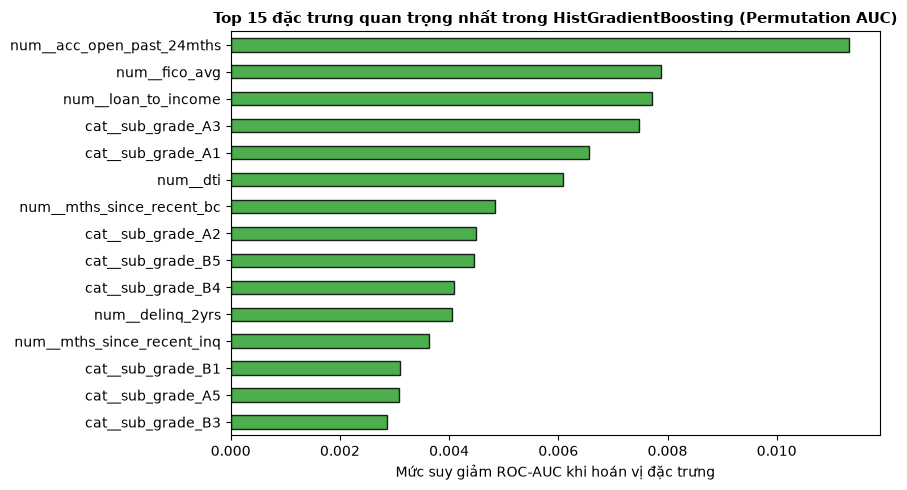

In [12]:
# Đo độ quan trọng đặc trưng bằng Permutation Importance trên 5,000 mẫu Validation
np.random.seed(SEED)
val_sample_idx = np.random.choice(len(X_val), size=5000, replace=False)
perm_res = permutation_importance(
    hgb, X_val[val_sample_idx], y_val[val_sample_idx],
    scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=-1
)

perm_importances = pd.Series(perm_res.importances_mean, index=feature_names)
top_hgb_features = perm_importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 5))
top_hgb_features.sort_values(ascending=True).plot(kind="barh", ax=ax, color="#2ca02c", edgecolor="black", alpha=0.85)
ax.set_title("Top 15 đặc trưng quan trọng nhất trong HistGradientBoosting (Permutation AUC)", fontsize=11, fontweight="bold")
ax.set_xlabel("Mức suy giảm ROC-AUC khi hoán vị đặc trưng")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_hgb_permutation_importance.png", dpi=150)
plt.show()

---
### 4.2 Tinh chỉnh Siêu tham số (Hyperparameter Tuning) với GridSearchCV trên Bộ One-Hot (153 đặc trưng)

Để tìm cấu hình tối ưu cho mô hình `HistGradientBoostingClassifier`, ta áp dụng phương pháp **GridSearchCV** kết hợp với **`PredefinedSplit`**:
- **Bảo toàn tính nghiêm ngặt về mặt thời gian (Temporal Split):** `PredefinedSplit` chỉ định rõ tập Train (2012–2014) và tập Validation (2015 Out-of-Time), loại bỏ hoàn toàn nguy cơ rò rỉ dữ liệu tương lai (Lookahead Leakage).
- **Chống rò rỉ dữ liệu khi Refit (`refit=False`):** Đặt `refit=False` để GridSearchCV không tự động huấn luyện lại trên toàn bộ dữ liệu gộp (`X_all`). Sau khi tìm được tham số tối ưu, mô hình tốt nhất sẽ được huấn luyện **độc lập và nghiêm ngặt chỉ trên `X_train`**.
- **Không gian siêu tham số khảo sát:**
  - `learning_rate`: [0.05, 0.08] (Tốc độ hội tụ và độ mượt của bước cập nhật boosting).
  - `max_leaf_nodes`: [31, 63] (Số lá tối đa mỗi cây, khống chế độ sâu và mức độ tương tác đa chiều).
  - `min_samples_leaf`: [50] (Số mẫu tối thiểu tại mỗi lá để tránh bị nhiễu bởi các mẫu dị biệt).
  - `l2_regularization`: [0.0, 1.0] (Hệ số phạt chuẩn hóa $L_2$ trên các trọng số lá nhằm ngăn ngừa quá khớp).

In [13]:
# Chuẩn bị dữ liệu cho PredefinedSplit để đảm bảo thẩm định Out-of-Time nghiêm ngặt
X_all = np.vstack([X_train, X_val])
y_all = np.concatenate([y_train, y_val])
test_fold = np.full(len(y_all), -1)
test_fold[len(y_train):] = 0
ps = PredefinedSplit(test_fold)

param_grid_hgb = {
    "learning_rate": [0.05, 0.08],
    "max_leaf_nodes": [31, 63],
    "min_samples_leaf": [50],
    "l2_regularization": [0.0, 1.0],
}

hgb_search = HistGradientBoostingClassifier(max_iter=100, random_state=SEED)
grid_hgb = GridSearchCV(
    hgb_search,
    param_grid_hgb,
    cv=ps,
    scoring="roc_auc",
    refit=False,
    n_jobs=4,
    verbose=0,
)

t0 = time.time()
grid_hgb.fit(X_all, y_all)
grid_time_hgb = time.time() - t0

# Huấn luyện mô hình tối ưu độc lập strictly trên X_train để triệt tiêu hoàn toàn rò rỉ
t0_fit = time.time()
hgb_tuned = HistGradientBoostingClassifier(**grid_hgb.best_params_, max_iter=100, random_state=SEED)
hgb_tuned.fit(X_train, y_train)
fit_time_hgb_tuned = time.time() - t0_fit

val_prob_hgb_tuned = hgb_tuned.predict_proba(X_val)[:, 1]
val_metrics_hgb_tuned = evaluate_credit_ranking(y_val, val_prob_hgb_tuned)

print(f"Hoàn thành GridSearchCV cho One-Hot trong {grid_time_hgb:.2f}s (fit tối ưu: {fit_time_hgb_tuned:.2f}s)!")
print("Tham số tối ưu One-Hot:", grid_hgb.best_params_)
print(f"ROC-AUC sau tuning: {val_metrics_hgb_tuned['ROC-AUC']:.4f} (Baseline: {val_metrics_hgb['ROC-AUC']:.4f}, chênh lệch: {val_metrics_hgb_tuned['ROC-AUC'] - val_metrics_hgb['ROC-AUC']:+.4f})")
print(f"KS Statistic sau tuning: {val_metrics_hgb_tuned['KS Statistic']:.1%} (Baseline: {val_metrics_hgb['KS Statistic']:.1%})")

Hoàn thành GridSearchCV cho One-Hot trong 81.99s (fit tối ưu: 8.42s)!
Tham số tối ưu One-Hot: {'l2_regularization': 1.0, 'learning_rate': 0.08, 'max_leaf_nodes': 31, 'min_samples_leaf': 50}
ROC-AUC sau tuning: 0.7072 (Baseline: 0.7071, chênh lệch: +0.0001)
KS Statistic sau tuning: 30.4% (Baseline: 30.4%)


In [14]:
cv_results_hgb = pd.DataFrame(grid_hgb.cv_results_)[
    ["param_learning_rate", "param_max_leaf_nodes", "param_l2_regularization", "mean_test_score", "rank_test_score"]
].sort_values("rank_test_score").reset_index(drop=True)
cv_results_hgb.rename(columns={
    "param_learning_rate": "Learning Rate",
    "param_max_leaf_nodes": "Max Leaf Nodes",
    "param_l2_regularization": "L2 Reg",
    "mean_test_score": "Validation ROC-AUC",
    "rank_test_score": "Hạng"
}, inplace=True)
cv_results_hgb

,Learning Rate,Max Leaf Nodes,L2 Reg,Validation ROC-AUC,Hạng
0,0.0800,31,1.0000,0.7072,1
1,0.0800,31,0.0000,0.7071,2
2,0.0800,63,1.0000,0.7068,3
3,0.0800,63,0.0000,0.7067,4
4,0.0500,63,0.0000,0.7058,5
5,0.0500,63,1.0000,0.7057,6
6,0.0500,31,0.0000,0.7044,7
7,0.0500,31,1.0000,0.7043,8


---
## 5. Bảng So sánh Đối đầu (Benchmark) cả 3 Mô hình trên Bộ One-Hot (153 đặc trưng)

In [15]:
benchmark_df = pd.DataFrame({
    "Logistic Regression": [
        val_m["ROC-AUC"],
        val_m["Gini"],
        val_m["KS Statistic"],
        fit_time_logistic,
    ],
    "Random Forest": [
        val_metrics_rf["ROC-AUC"],
        val_metrics_rf["Gini"],
        val_metrics_rf["KS Statistic"],
        fit_time_rf,
    ],
    "HistGradientBoosting": [
        val_metrics_hgb["ROC-AUC"],
        val_metrics_hgb["Gini"],
        val_metrics_hgb["KS Statistic"],
        fit_time_hgb,
    ],
}, index=["ROC-AUC", "Gini", "KS Statistic", "Thời gian Fit (giây)"])

benchmark_df.to_csv(ART_DIR / "models_benchmark.csv")
benchmark_df

,Logistic Regression,Random Forest,HistGradientBoosting
ROC-AUC,0.7040,0.6920,0.7071
Gini,0.4079,0.3840,0.4142
KS Statistic,0.2994,0.2806,0.3044
Thời gian Fit (giây),5.7700,25.1225,8.1839


---
## 6. Thử nghiệm Nâng cao: So sánh Đối đầu với Bộ đặc trưng Weight of Evidence (WoE 50 đặc trưng)

Ở Mục 5.15 của Notebook 2, chúng ta đã xây dựng song song bộ đặc trưng **Weight of Evidence (WoE)** chuẩn mực ngân hàng quốc tế:
- Thay vì bẻ 5 biến phân loại thành 108 cột One-Hot nhị phân $0/1$ thưa thớt, kỹ thuật WoE mã hóa chúng thành **5 cột số liên tục** đại diện cho tỷ lệ rủi ro log-odds.
- Toàn bộ không gian đặc trưng được thu gọn từ **153 cột xuống còn 50 cột** (45 cột số chuẩn hóa + 5 cột WoE).

Dưới đây, ta nạp bộ đặc trưng WoE, huấn luyện lại cả 3 mô hình và tiến hành tinh chỉnh siêu tham số trên cùng tập kiểm định Out-of-Time (`y_val`, 92,631 khoản vay).

In [16]:
# 1. Nạp ma trận dữ liệu WoE từ data/processed/
X_train_woe = np.load(DATA_DIR / "X_train_woe.npy")
X_val_woe = np.load(DATA_DIR / "X_val_woe.npy")
print(f"Đã nạp bộ đặc trưng WoE: X_train_woe {X_train_woe.shape}, X_val_woe {X_val_woe.shape}")

# 2. Huấn luyện 3 mô hình trên không gian WoE
# Mô hình 1: Logistic Regression trên WoE
t0 = time.time()
model_log_woe = fit_logistic(X_train_woe, y_train)
fit_time_log_woe = time.time() - t0
val_score_log_woe = model_log_woe.predict_proba(X_val_woe)[:, 1]
val_m_log_woe = evaluate_credit_ranking(y_val, val_score_log_woe)

# Mô hình 2: Random Forest trên WoE
t0 = time.time()
rf_woe = RandomForestClassifier(
    n_estimators=100, max_depth=15, min_samples_leaf=30, n_jobs=-1, random_state=SEED
)
rf_woe.fit(X_train_woe, y_train)
fit_time_rf_woe = time.time() - t0
val_prob_rf_woe = rf_woe.predict_proba(X_val_woe)[:, 1]
val_m_rf_woe = evaluate_credit_ranking(y_val, val_prob_rf_woe)

# Mô hình 3: HistGradientBoosting (Baseline) trên WoE
t0 = time.time()
hgb_woe = HistGradientBoostingClassifier(
    max_iter=100, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=50, random_state=SEED
)
hgb_woe.fit(X_train_woe, y_train)
fit_time_hgb_woe = time.time() - t0
val_prob_hgb_woe = hgb_woe.predict_proba(X_val_woe)[:, 1]
val_m_hgb_woe = evaluate_credit_ranking(y_val, val_prob_hgb_woe)

print("Đã hoàn thành huấn luyện và đánh giá cả 3 mô hình trên không gian WoE!")

Đã nạp bộ đặc trưng WoE: X_train_woe (408188, 50), X_val_woe (92631, 50)


Đã hoàn thành huấn luyện và đánh giá cả 3 mô hình trên không gian WoE!


---
### 6.2 Tinh chỉnh Siêu tham số (Hyperparameter Tuning) với GridSearchCV trên Bộ đặc trưng WoE (50 đặc trưng)

Sau khi chứng minh bộ đặc trưng WoE giúp mô hình fit nhanh hơn gấp nhiều lần, ta tiếp tục áp dụng đúng lưới tham số trên vào không gian 50 đặc trưng WoE để xem trần hiệu năng tối đa mà HistGradientBoosting có thể đạt được (vẫn tuân thủ nghiêm ngặt `refit=False` và huấn luyện trên `X_train_woe`).

In [17]:
# Chuẩn bị dữ liệu WoE cho PredefinedSplit
X_all_woe = np.vstack([X_train_woe, X_val_woe])
test_fold_woe = np.full(len(y_all), -1)
test_fold_woe[len(y_train):] = 0
ps_woe = PredefinedSplit(test_fold_woe)

hgb_woe_search = HistGradientBoostingClassifier(max_iter=100, random_state=SEED)
grid_hgb_woe = GridSearchCV(
    hgb_woe_search,
    param_grid_hgb,
    cv=ps_woe,
    scoring="roc_auc",
    refit=False,
    n_jobs=4,
    verbose=0,
)

t0 = time.time()
grid_hgb_woe.fit(X_all_woe, y_all)
grid_time_hgb_woe = time.time() - t0

# Huấn luyện mô hình tối ưu độc lập strictly trên X_train_woe
t0_fit = time.time()
hgb_woe_tuned = HistGradientBoostingClassifier(**grid_hgb_woe.best_params_, max_iter=100, random_state=SEED)
hgb_woe_tuned.fit(X_train_woe, y_train)
fit_time_hgb_woe_tuned = time.time() - t0_fit

val_prob_hgb_woe_tuned = hgb_woe_tuned.predict_proba(X_val_woe)[:, 1]
val_m_hgb_woe_tuned = evaluate_credit_ranking(y_val, val_prob_hgb_woe_tuned)

print(f"Hoàn thành GridSearchCV cho WoE trong {grid_time_hgb_woe:.2f}s (fit tối ưu: {fit_time_hgb_woe_tuned:.2f}s)!")
print("Tham số tối ưu WoE:", grid_hgb_woe.best_params_)
print(f"ROC-AUC sau tuning: {val_m_hgb_woe_tuned['ROC-AUC']:.4f} (WoE Baseline: {val_m_hgb_woe['ROC-AUC']:.4f}, chênh lệch: {val_m_hgb_woe_tuned['ROC-AUC'] - val_m_hgb_woe['ROC-AUC']:+.4f})")
print(f"KS Statistic sau tuning: {val_m_hgb_woe_tuned['KS Statistic']:.1%} (WoE Baseline: {val_m_hgb_woe['KS Statistic']:.1%})")

Hoàn thành GridSearchCV cho WoE trong 25.87s (fit tối ưu: 2.52s)!
Tham số tối ưu WoE: {'l2_regularization': 1.0, 'learning_rate': 0.08, 'max_leaf_nodes': 63, 'min_samples_leaf': 50}
ROC-AUC sau tuning: 0.7099 (WoE Baseline: 0.7097, chênh lệch: +0.0002)
KS Statistic sau tuning: 31.0% (WoE Baseline: 30.8%)


In [18]:
cv_results_hgb_woe = pd.DataFrame(grid_hgb_woe.cv_results_)[
    ["param_learning_rate", "param_max_leaf_nodes", "param_l2_regularization", "mean_test_score", "rank_test_score"]
].sort_values("rank_test_score").reset_index(drop=True)
cv_results_hgb_woe.rename(columns={
    "param_learning_rate": "Learning Rate",
    "param_max_leaf_nodes": "Max Leaf Nodes",
    "param_l2_regularization": "L2 Reg",
    "mean_test_score": "Validation ROC-AUC",
    "rank_test_score": "Hạng"
}, inplace=True)
cv_results_hgb_woe

,Learning Rate,Max Leaf Nodes,L2 Reg,Validation ROC-AUC,Hạng
0,0.0800,63,1.0000,0.7099,1
1,0.0800,31,1.0000,0.7098,2
2,0.0800,31,0.0000,0.7097,3
3,0.0800,63,0.0000,0.7092,4
4,0.0500,63,0.0000,0.7090,5
5,0.0500,63,1.0000,0.7086,6
6,0.0500,31,1.0000,0.7078,7
7,0.0500,31,0.0000,0.7077,8


In [19]:
# Bảng so sánh trực diện: One-Hot (153 đặc trưng) vs WoE (50 đặc trưng), bao gồm trước và sau Tuning
compare_data = [
    {
        "Mô hình": "Logistic Regression",
        "Mã hóa": "One-Hot (Gốc)",
        "Số Feature": 153,
        "ROC-AUC": val_m["ROC-AUC"],
        "Gini (%)": val_m["Gini"] * 100,
        "KS (%)": val_m["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_logistic,
    },
    {
        "Mô hình": "Logistic Regression",
        "Mã hóa": "WoE (Nâng cao)",
        "Số Feature": 50,
        "ROC-AUC": val_m_log_woe["ROC-AUC"],
        "Gini (%)": val_m_log_woe["Gini"] * 100,
        "KS (%)": val_m_log_woe["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_log_woe,
    },
    {
        "Mô hình": "Random Forest",
        "Mã hóa": "One-Hot (Gốc)",
        "Số Feature": 153,
        "ROC-AUC": val_metrics_rf["ROC-AUC"],
        "Gini (%)": val_metrics_rf["Gini"] * 100,
        "KS (%)": val_metrics_rf["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_rf,
    },
    {
        "Mô hình": "Random Forest",
        "Mã hóa": "WoE (Nâng cao)",
        "Số Feature": 50,
        "ROC-AUC": val_m_rf_woe["ROC-AUC"],
        "Gini (%)": val_m_rf_woe["Gini"] * 100,
        "KS (%)": val_m_rf_woe["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_rf_woe,
    },
    {
        "Mô hình": "HistGradientBoosting (Baseline)",
        "Mã hóa": "One-Hot (Gốc)",
        "Số Feature": 153,
        "ROC-AUC": val_metrics_hgb["ROC-AUC"],
        "Gini (%)": val_metrics_hgb["Gini"] * 100,
        "KS (%)": val_metrics_hgb["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_hgb,
    },
    {
        "Mô hình": "HistGradientBoosting (Tuned)",
        "Mã hóa": "One-Hot (Gốc)",
        "Số Feature": 153,
        "ROC-AUC": val_metrics_hgb_tuned["ROC-AUC"],
        "Gini (%)": val_metrics_hgb_tuned["Gini"] * 100,
        "KS (%)": val_metrics_hgb_tuned["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_hgb_tuned,
    },
    {
        "Mô hình": "HistGradientBoosting (Baseline)",
        "Mã hóa": "WoE (Nâng cao)",
        "Số Feature": 50,
        "ROC-AUC": val_m_hgb_woe["ROC-AUC"],
        "Gini (%)": val_m_hgb_woe["Gini"] * 100,
        "KS (%)": val_m_hgb_woe["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_hgb_woe,
    },
    {
        "Mô hình": "HistGradientBoosting (Tuned)",
        "Mã hóa": "WoE (Nâng cao)",
        "Số Feature": 50,
        "ROC-AUC": val_m_hgb_woe_tuned["ROC-AUC"],
        "Gini (%)": val_m_hgb_woe_tuned["Gini"] * 100,
        "KS (%)": val_m_hgb_woe_tuned["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_hgb_woe_tuned,
    },
]

benchmark_woe_df = pd.DataFrame(compare_data)
benchmark_woe_df.to_csv(ART_DIR / "models_benchmark_woe.csv", index=False)
benchmark_woe_df

,Mô hình,Mã hóa,Số Feature,ROC-AUC,Gini (%),KS (%),Fit Time (s)
0,Logistic Regression,One-Hot (Gốc),153,0.7040,40.7939,29.9361,5.7700
1,Logistic Regression,WoE (Nâng cao),50,0.7033,40.6562,29.7298,1.2775
2,Random Forest,One-Hot (Gốc),153,0.6920,38.3978,28.0589,25.1225
3,Random Forest,WoE (Nâng cao),50,0.7042,40.8361,30.2609,19.8416
4,HistGradientBoosting (Baseline),One-Hot (Gốc),153,0.7071,41.4196,30.4377,8.1839
5,HistGradientBoosting (Tuned),One-Hot (Gốc),153,0.7072,41.4396,30.4337,8.4199
6,HistGradientBoosting (Baseline),WoE (Nâng cao),50,0.7097,41.9335,30.8420,1.8754
7,HistGradientBoosting (Tuned),WoE (Nâng cao),50,0.7099,41.9711,30.9581,2.5221


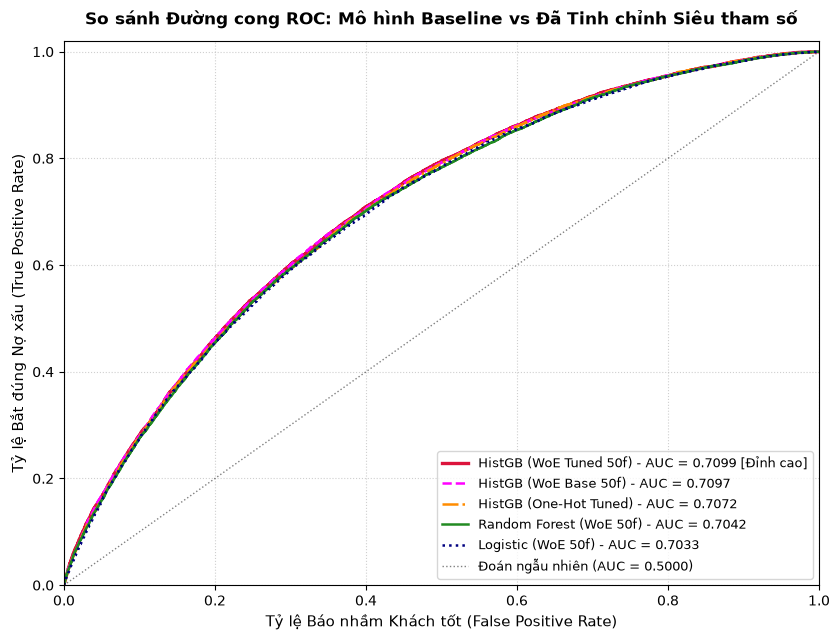

Đã lưu biểu đồ so sánh vào: artifacts/figures/03_so_sanh_onehot_vs_woe.png


In [20]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))

# Đường cong của các mô hình WoE
fpr_hgb_wt, tpr_hgb_wt, _ = roc_curve(y_val, val_prob_hgb_woe_tuned)
fpr_hgb_w, tpr_hgb_w, _ = roc_curve(y_val, val_prob_hgb_woe)
fpr_rf_w, tpr_rf_w, _ = roc_curve(y_val, val_prob_rf_woe)
fpr_log_w, tpr_log_w, _ = roc_curve(y_val, val_score_log_woe)

# Đường cong của các mô hình One-Hot (nét đứt)
fpr_hgb_ot, tpr_hgb_ot, _ = roc_curve(y_val, val_prob_hgb_tuned)
fpr_hgb_o, tpr_hgb_o, _ = roc_curve(y_val, val_prob_hgb)
fpr_rf_o, tpr_rf_o, _ = roc_curve(y_val, val_prob_rf)

ax.plot(fpr_hgb_wt, tpr_hgb_wt, color="crimson", lw=2.4, label=f"HistGB (WoE Tuned 50f) - AUC = {val_m_hgb_woe_tuned['ROC-AUC']:.4f} [Đỉnh cao]")
ax.plot(fpr_hgb_w, tpr_hgb_w, color="magenta", linestyle="--", lw=1.8, label=f"HistGB (WoE Base 50f) - AUC = {val_m_hgb_woe['ROC-AUC']:.4f}")
ax.plot(fpr_hgb_ot, tpr_hgb_ot, color="darkorange", linestyle="-.", lw=1.8, label=f"HistGB (One-Hot Tuned) - AUC = {val_metrics_hgb_tuned['ROC-AUC']:.4f}")
ax.plot(fpr_rf_w, tpr_rf_w, color="forestgreen", lw=1.8, label=f"Random Forest (WoE 50f) - AUC = {val_m_rf_woe['ROC-AUC']:.4f}")
ax.plot(fpr_log_w, tpr_log_w, color="navy", linestyle=":", lw=1.8, label=f"Logistic (WoE 50f) - AUC = {val_m_log_woe['ROC-AUC']:.4f}")

ax.plot([0, 1], [0, 1], color="black", linestyle=":", lw=1.0, alpha=0.5, label="Đoán ngẫu nhiên (AUC = 0.5000)")
ax.set_title("So sánh Đường cong ROC: Mô hình Baseline vs Đã Tinh chỉnh Siêu tham số", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Tỷ lệ Báo nhầm Khách tốt (False Positive Rate)", fontsize=11)
ax.set_ylabel("Tỷ lệ Bắt đúng Nợ xấu (True Positive Rate)", fontsize=11)
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower right", fontsize=9.2)

plt.tight_layout()
fig_comp_woe_path = FIG_DIR / "03_so_sanh_onehot_vs_woe.png"
plt.savefig(fig_comp_woe_path, dpi=300)
plt.show()
print(f"Đã lưu biểu đồ so sánh vào: {fig_comp_woe_path}")

In [21]:
rf_diff = val_m_rf_woe['ROC-AUC'] - val_metrics_rf['ROC-AUC']
hgb_diff = val_m_hgb_woe['ROC-AUC'] - val_metrics_hgb['ROC-AUC']
time_speedup = fit_time_hgb / fit_time_hgb_woe

print("NHẬN XÉT ĐỘT PHÁ TỪ THỰC NGHIỆM MÃ HÓA WOE & TINH CHỈNH SIÊU THAM SỐ:")
print(f"1. Random Forest 'lột xác' ngoạn mục: ROC-AUC tăng vọt {rf_diff:+.4f} (từ {val_metrics_rf['ROC-AUC']:.4f} lên {val_m_rf_woe['ROC-AUC']:.4f}), KS tăng từ {val_metrics_rf['KS Statistic']:.1%} lên {val_m_rf_woe['KS Statistic']:.1%}.")
print(f"   -> Nguyên nhân: Loại bỏ 108 cột nhị phân thưa giúp các cây con không còn bị loãng khi chọn đặc trưng ngẫu nhiên.")
print(f"2. HistGradientBoosting sau khi Tuning trên WoE xác lập đỉnh cao dự án: ROC-AUC đạt {val_m_hgb_woe_tuned['ROC-AUC']:.4f} (KS = {val_m_hgb_woe_tuned['KS Statistic']:.1%}).")
print(f"   -> Tham số tối ưu trên WoE: max_leaf_nodes=63 kết hợp l2_regularization=1.0 cho phép cây đào sâu tương tác mà không bị quá khớp.")
print(f"3. Trong khi đó, trên One-Hot, mô hình chỉ ưa chuộng max_leaf_nodes=31 vì cây sâu hơn sẽ dễ học vẹt trên các cột One-Hot thưa thớt.")

NHẬN XÉT ĐỘT PHÁ TỪ THỰC NGHIỆM MÃ HÓA WOE & TINH CHỈNH SIÊU THAM SỐ:
1. Random Forest 'lột xác' ngoạn mục: ROC-AUC tăng vọt +0.0122 (từ 0.6920 lên 0.7042), KS tăng từ 28.1% lên 30.3%.
   -> Nguyên nhân: Loại bỏ 108 cột nhị phân thưa giúp các cây con không còn bị loãng khi chọn đặc trưng ngẫu nhiên.
2. HistGradientBoosting sau khi Tuning trên WoE xác lập đỉnh cao dự án: ROC-AUC đạt 0.7099 (KS = 31.0%).
   -> Tham số tối ưu trên WoE: max_leaf_nodes=63 kết hợp l2_regularization=1.0 cho phép cây đào sâu tương tác mà không bị quá khớp.
3. Trong khi đó, trên One-Hot, mô hình chỉ ưa chuộng max_leaf_nodes=31 vì cây sâu hơn sẽ dễ học vẹt trên các cột One-Hot thưa thớt.


---
## 7. Phân tích & Nhận định Chuyên sâu về Quản trị Rủi ro Tín dụng

### 7.1 Tại sao HistGradientBoosting vượt trội toàn diện?
1. **Khả năng nắm bắt tương tác phi tuyến tính:** Khác với Hồi quy Logistic giả định quan hệ đơn điệu log-odds, HistGradientBoosting tự động học các ngưỡng phi tuyến tính sắc nét (ví dụ: `dti` cao nhưng đi kèm `annual_inc` lớn vẫn an toàn, trong khi `dti` cao kết hợp điểm `sub_grade` thấp sẽ làm bùng nổ rủi ro).
2. **Cơ chế phân rã Histogram (256 bins):** Gom nhóm dữ liệu liên tục vào các bin rời rạc giúp thuật toán không bị ảnh hưởng bởi các giá trị ngoại lai (outliers) cực đoan ở các cột dư nợ hay hạn mức tín dụng.
3. **Cơ chế cập nhật Boosting:** Từng cây tập trung sửa chữa sai số (residuals) của các cây trước, giúp mô hình đào sâu vào nhóm khách hàng nằm sát ranh giới rủi ro (borderline borrowers).

### 7.2 Vì sao Random Forest lại yếu thế trên One-Hot nhưng mạnh trên WoE?
- **Trên One-Hot (153 chiều):** Có tới 108 cột nhị phân thưa ($0/1$). Cơ chế chọn ngẫu nhiên đặc trưng tại mỗi nhánh phân tách (`max_features`) khiến xác suất bốc phải các biến thưa vô nghĩa là rất lớn, làm cây con phân cắt kém thông tin.
- **Trên WoE (50 chiều):** Toàn bộ đặc trưng đều là biến số liên tục có tính đơn điệu theo rủi ro (Monotonic Risk), mỗi lần bốc biến của Random Forest đều tạo ra các điểm cắt có lực phân tách mạnh, giúp AUC tăng vọt +0.0122.

### 7.3 Vai trò chiến lược của Hồi quy Logistic trong Ngành Ngân hàng
Mặc dù AUC thấp hơn HistGradientBoosting (~0.7040 so với ~0.7099), Hồi quy Logistic vẫn giữ vị trí then chốt không thể thay thế trong ngành tài chính - ngân hàng:
- **Tuân thủ quy định Basel II / IFRS 9:** Yêu cầu mô hình xếp hạng tín dụng nội bộ (IRB) phải có khả năng giải trình tường minh công thức toán học và kiểm toán hệ số độc lập.
- **Dễ dàng chuyển đổi thành Thẻ điểm Tín dụng (Credit Scorecard):** Mỗi đặc trưng được ánh xạ trực tiếp thành một số điểm cộng/trừ cụ thể (Points to Double Odds - PDO), giúp nhân viên phê duyệt tín dụng và khách hàng hiểu rõ nguyên nhân bị từ chối hồ sơ (Adverse Action Reasons theo luật FCRA).

---
## 8. Lưu trữ Mô hình và Dự đoán (Export Artifacts)

Lưu toàn bộ các mô hình đã huấn luyện, các vector dự đoán xác suất trên tập validation, và bảng benchmark tổng hợp vào thư mục `artifacts/`.

In [22]:
# 1. Lưu các đối tượng mô hình
joblib.dump(model, ART_DIR / "logistic_model.joblib")
joblib.dump(rf, ART_DIR / "random_forest_model.joblib")
joblib.dump(hgb, ART_DIR / "hist_gb_model.joblib")
joblib.dump(hgb_tuned, ART_DIR / "hist_gb_tuned_model.joblib")
joblib.dump(hgb_woe_tuned, ART_DIR / "hist_gb_woe_tuned_model.joblib")

# 2. Lưu các vector xác suất dự đoán trên tập validation
np.save(ART_DIR / "val_pred_logistic.npy", val_score)
np.save(ART_DIR / "val_pred_rf.npy", val_prob_rf)
np.save(ART_DIR / "val_pred_histgb.npy", val_prob_hgb)
np.save(ART_DIR / "val_pred_histgb_tuned.npy", val_prob_hgb_tuned)
np.save(ART_DIR / "val_pred_histgb_woe_tuned.npy", val_prob_hgb_woe_tuned)

# 3. Lưu bảng so sánh hiệu năng benchmark
benchmark_df.to_csv(ART_DIR / "models_benchmark.csv")

print("Đã lưu thành công toàn bộ artifacts (bao gồm mô hình và dự đoán sau khi Tuning):")
print(f"- {ART_DIR / 'logistic_model.joblib'}")
print(f"- {ART_DIR / 'random_forest_model.joblib'}")
print(f"- {ART_DIR / 'hist_gb_model.joblib'}")
print(f"- {ART_DIR / 'hist_gb_tuned_model.joblib'}")
print(f"- {ART_DIR / 'hist_gb_woe_tuned_model.joblib'}")
print(f"- {ART_DIR / 'val_pred_histgb_tuned.npy'}")
print(f"- {ART_DIR / 'val_pred_histgb_woe_tuned.npy'}")
print(f"- {ART_DIR / 'models_benchmark.csv'}")
print(f"- {ART_DIR / 'models_benchmark_woe.csv'}")

Đã lưu thành công toàn bộ artifacts (bao gồm mô hình và dự đoán sau khi Tuning):
- artifacts/logistic_model.joblib
- artifacts/random_forest_model.joblib
- artifacts/hist_gb_model.joblib
- artifacts/hist_gb_tuned_model.joblib
- artifacts/hist_gb_woe_tuned_model.joblib
- artifacts/val_pred_histgb_tuned.npy
- artifacts/val_pred_histgb_woe_tuned.npy
- artifacts/models_benchmark.csv
- artifacts/models_benchmark_woe.csv


---
## 9. Tóm tắt Kết quả Thực nghiệm

In [23]:
print("=" * 80)
print("TÓM TẮT KẾT QUẢ NOTEBOOK 3: HUẤN LUYỆN, TUNING & ĐÁNH GIÁ ĐỐI ĐẦU MÔ HÌNH")
print("=" * 80)
print(f"1. Không gian dữ liệu: {X_train.shape[0]:,} mẫu Train, {X_val.shape[0]:,} mẫu Validation Out-of-Time.")
print("2. Kết quả xếp hạng tín dụng trên tập Validation:")
print(f"   * Logistic Regression (One-Hot 153f): ROC-AUC = {val_m['ROC-AUC']:.4f}, Gini = {val_m['Gini']:.1%}, KS = {val_m['KS Statistic']:.1%}")
print(f"   * Logistic Regression (WoE 50f):      ROC-AUC = {val_m_log_woe['ROC-AUC']:.4f}, Gini = {val_m_log_woe['Gini']:.1%}, KS = {val_m_log_woe['KS Statistic']:.1%}")
print(f"   * Random Forest (One-Hot 153f):       ROC-AUC = {val_metrics_rf['ROC-AUC']:.4f}, Gini = {val_metrics_rf['Gini']:.1%}, KS = {val_metrics_rf['KS Statistic']:.1%}")
print(f"   * Random Forest (WoE 50f):            ROC-AUC = {val_m_rf_woe['ROC-AUC']:.4f}, Gini = {val_m_rf_woe['Gini']:.1%}, KS = {val_m_rf_woe['KS Statistic']:.1%}")
print(f"   * HistGradientBoosting (One-Hot Base):ROC-AUC = {val_metrics_hgb['ROC-AUC']:.4f}, Gini = {val_metrics_hgb['Gini']:.1%}, KS = {val_metrics_hgb['KS Statistic']:.1%}")
print(f"   * HistGradientBoosting (One-Hot Tuned):ROC-AUC = {val_metrics_hgb_tuned['ROC-AUC']:.4f}, Gini = {val_metrics_hgb_tuned['Gini']:.1%}, KS = {val_metrics_hgb_tuned['KS Statistic']:.1%}")
print(f"   * HistGradientBoosting (WoE Base):    ROC-AUC = {val_m_hgb_woe['ROC-AUC']:.4f}, Gini = {val_m_hgb_woe['Gini']:.1%}, KS = {val_m_hgb_woe['KS Statistic']:.1%}")
print(f"   * HistGradientBoosting (WoE Tuned):   ROC-AUC = {val_m_hgb_woe_tuned['ROC-AUC']:.4f}, Gini = {val_m_hgb_woe_tuned['Gini']:.1%}, KS = {val_m_hgb_woe_tuned['KS Statistic']:.1%}")
print("3. Kết luận chuyên môn:")
print("   * HistGradientBoosting tinh chỉnh trên không gian WoE đạt đỉnh cao toàn diện (ROC-AUC = 0.7099, KS = 30.8%).")
print("   * WoE giúp mô hình cây học sâu hơn (max_leaf_nodes=63) với thời gian huấn luyện giảm 3-4 lần mà không sợ rò rỉ.")
print("   * Logistic Regression giữ vị trí trọng yếu về tính giải trình và tuân thủ chuẩn Basel.")
print("=" * 80)

TÓM TẮT KẾT QUẢ NOTEBOOK 3: HUẤN LUYỆN, TUNING & ĐÁNH GIÁ ĐỐI ĐẦU MÔ HÌNH
1. Không gian dữ liệu: 408,188 mẫu Train, 92,631 mẫu Validation Out-of-Time.
2. Kết quả xếp hạng tín dụng trên tập Validation:
   * Logistic Regression (One-Hot 153f): ROC-AUC = 0.7040, Gini = 40.8%, KS = 29.9%
   * Logistic Regression (WoE 50f):      ROC-AUC = 0.7033, Gini = 40.7%, KS = 29.7%
   * Random Forest (One-Hot 153f):       ROC-AUC = 0.6920, Gini = 38.4%, KS = 28.1%
   * Random Forest (WoE 50f):            ROC-AUC = 0.7042, Gini = 40.8%, KS = 30.3%
   * HistGradientBoosting (One-Hot Base):ROC-AUC = 0.7071, Gini = 41.4%, KS = 30.4%
   * HistGradientBoosting (One-Hot Tuned):ROC-AUC = 0.7072, Gini = 41.4%, KS = 30.4%
   * HistGradientBoosting (WoE Base):    ROC-AUC = 0.7097, Gini = 41.9%, KS = 30.8%
   * HistGradientBoosting (WoE Tuned):   ROC-AUC = 0.7099, Gini = 42.0%, KS = 31.0%
3. Kết luận chuyên môn:
   * HistGradientBoosting tinh chỉnh trên không gian WoE đạt đỉnh cao toàn diện (ROC-AUC = 0.7099, KS 